# Background

- **Author**: `詹明翰`
- **Created At**: `2026-11-06`
- **Research Motivation and Context (why are we interested in the findings?)：** 延續 [PCA與群數比較](夜間事故PCA與分群比較.ipynb)，本分析以[一般 one-hot 分群矩陣](../data/processed/taipei_2025_nighttime_clustering_matrix_unweighted.csv)的K=5作主要規格，並以[類別區塊加權矩陣](../data/processed/taipei_2025_nighttime_clustering_matrix_block_weighted.csv)的K=5作尺度敏感度檢查。原始profile變數來自[正式分群輸入](../data/processed/taipei_2025_nighttime_clustering_input.csv)，照明與死亡結果由目前磁碟版本的[敘述性統計輸入](../data/processed/taipei_2025_descriptive.csv)依 `record_id` 一對一合併；資料準備與排除規則見[分群資料說明](../data/processed/taipei_2025_nighttime_clustering_documentation.ipynb)。照明與死亡未用於PCA或K-means，也不反過來決定群數。
- **Main Findings and Takeaways：** K=5主要形成秋冬傍晚50型（1,664件）、夏季晚間50型（1,246件）、深夜凌晨型（1,186件）、春季晚間50型（1,534件）與低速限晚間型（1,071件）。主要規格與類別區塊加權K=5的ARI為0.843，最佳標籤對齊後有93.2%事故落在對應群，表示五群對尺度設定具有一定穩健性；但profile顯示群組主要由季節、夜間時段與速限區分，道路型態及事故位置差異較小。深夜凌晨型的照明未開啟／故障為7.84%、無照明2.28%，合計10.12%，高於其他群約4.69%至7.19%；照明三分類與群組的卡方檢定p值小於0.001，但Cramér’s V僅0.051，屬很小的描述性關聯。全樣本只有26件24小時內死亡事故，其中深夜凌晨型15件、比例1.26%（Wilson 95% CI 0.77%–2.08%），其他群約0.12%–0.32%；事件稀少，不作因果或複雜模型解讀。
- **Future Direction：** preliminary report可暫以K=5呈現時間、季節與速限情境，但須明列道路情境區分較弱；再以K=2及K=6檢查profile與照明結論是否改變。若時間允許，補充群組地理分布及速限0紀錄的敏感度。


In [1]:
from pathlib import Path
import hashlib
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.optimize import linear_sum_assignment
from scipy.stats import chi2_contingency
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = ['Microsoft JhengHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
RANDOM_STATE = 5166
PRIMARY_K = 5


In [2]:
def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / 'AGENTS.md').is_file() and (candidate / 'templates').is_dir():
            return candidate
    raise FileNotFoundError('請從含 AGENTS.md 與 templates/ 的學生專案內開啟本 Notebook。')


def project_file(relative_path):
    rel = Path(relative_path)
    if rel.is_absolute() or '..' in rel.parts:
        raise ValueError(f'必須使用明確的專案相對路徑：{relative_path}')
    path = (PROJECT_ROOT / rel).resolve()
    allowed = (PROJECT_ROOT / 'data' / 'processed').resolve()
    if not path.is_relative_to(allowed) or not path.is_file():
        raise FileNotFoundError(path)
    return path


def sha256_file(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


PROJECT_ROOT = find_project_root()
ASSET_DIR = PROJECT_ROOT / 'finding' / 'assets' / 'nighttime_cluster_profiles'
ASSET_DIR.mkdir(parents=True, exist_ok=True)
FILES = {
    'semantic': 'data/processed/taipei_2025_nighttime_clustering_input.csv',
    'unweighted': 'data/processed/taipei_2025_nighttime_clustering_matrix_unweighted.csv',
    'block_weighted': 'data/processed/taipei_2025_nighttime_clustering_matrix_block_weighted.csv',
    'descriptive': 'data/processed/taipei_2025_descriptive.csv',
}
EXPECTED_SHA256 = {
    'semantic': '02869cf20f9362a6bf3d54ca2ca8e4b75dca983069d220bc527d6dbe9122b0f1',
    'unweighted': '6a6d92299d333cce4dcc9b1f425faa28e0d8a20ba2b76dc7221ecc1d85328ab6',
    'block_weighted': '88173998c8c597af0ce653e1b6764b03ed2582cdb961c3975de12079ab304e37',
    'descriptive': 'e98fb4c4d62bd08440d58bbe17af7f3c03b48b4bb91e02bf306e48dda8250465',
}
paths = {key: project_file(path) for key, path in FILES.items()}
for key, path in paths.items():
    if sha256_file(path) != EXPECTED_SHA256[key]:
        raise ValueError(f'{key} 輸入版本已改變；請先辨識新版本。')

semantic = pd.read_csv(paths['semantic'], encoding='utf-8-sig')
unweighted = pd.read_csv(paths['unweighted'], encoding='utf-8-sig')
block_weighted = pd.read_csv(paths['block_weighted'], encoding='utf-8-sig')
descriptive = pd.read_csv(paths['descriptive'], encoding='utf-8-sig', low_memory=False)
for frame in [semantic, unweighted, block_weighted]:
    assert len(frame) == 6701 and frame['record_id'].is_unique
assert descriptive['record_id'].is_unique
assert semantic['record_id'].tolist() == unweighted['record_id'].tolist()
assert semantic['record_id'].tolist() == block_weighted['record_id'].tolist()

outcome_columns = ['record_id', '光線', 'lighting_label', 'fatal24', 'district', 'weather_label', 'road_form_label']
analysis = semantic.merge(
    descriptive[outcome_columns], on='record_id', how='left', validate='one_to_one',
)
assert len(analysis) == 6701 and analysis['record_id'].is_unique
assert analysis['光線'].isin([5, 6, 7]).all()
assert analysis['fatal24'].isin([0, 1]).all()
analysis['crash_datetime'] = pd.to_datetime(analysis['crash_datetime'], errors='raise')
analysis['hour'] = analysis['crash_datetime'].dt.hour
analysis['month'] = analysis['crash_datetime'].dt.month
analysis['time_period'] = np.select(
    [analysis['hour'].between(17, 20), analysis['hour'].between(21, 23),
     analysis['hour'].between(0, 2), analysis['hour'].between(3, 6)],
    ['17–20時', '21–23時', '00–02時', '03–06時'], default='其他',
)
assert not analysis['time_period'].eq('其他').any()

print({'analysis_n': len(analysis), 'matched_outcomes_n': analysis['lighting_label'].notna().sum(),
       'fatal_nonmissing_n': analysis['fatal24'].notna().sum(), 'input_hashes_verified': True})
display(analysis.head(10))


{'analysis_n': 6701, 'matched_outcomes_n': 6701, 'fatal_nonmissing_n': 6701, 'input_hashes_verified': True}


,record_id,crash_datetime,speed_limit,hour_sin,hour_cos,month_sin,month_cos,weather_code,road_class_code,road_form_code,crash_position_code,光線,lighting_label,fatal24,district,weather_label,road_form_label,hour,month,time_period
0,1,2025-01-01 00:18:00,40,0.000000,1.000000e+00,0.0,1.0,8,5,14,9,5.0,有照明且開啟,0.0,中山區,晴,直路,0,1,00–02時
1,2,2025-01-01 00:31:00,50,0.000000,1.000000e+00,0.0,1.0,7,5,14,9,5.0,有照明且開啟,0.0,文山區,陰,直路,0,1,00–02時
2,3,2025-01-01 00:35:00,50,0.000000,1.000000e+00,0.0,1.0,7,5,5,1,5.0,有照明且開啟,0.0,中山區,陰,多岔路,0,1,00–02時
3,4,2025-01-01 00:41:00,50,0.000000,1.000000e+00,0.0,1.0,7,5,14,7,5.0,有照明且開啟,0.0,中山區,陰,直路,0,1,00–02時
4,5,2025-01-01 00:57:00,50,0.000000,1.000000e+00,0.0,1.0,7,5,3,1,5.0,有照明且開啟,0.0,南港區,陰,三岔路,0,1,00–02時
5,6,2025-01-01 01:34:00,30,0.258819,9.659258e-01,0.0,1.0,7,5,3,1,5.0,有照明且開啟,0.0,信義區,陰,三岔路,1,1,00–02時
6,7,2025-01-01 02:15:00,50,0.500000,8.660254e-01,0.0,1.0,7,5,14,9,5.0,有照明且開啟,0.0,信義區,陰,直路,2,1,00–02時
7,8,2025-01-01 06:26:00,30,1.000000,6.123234e-17,0.0,1.0,8,5,12,9,7.0,無照明,0.0,文山區,晴,坡路,6,1,03–06時
8,9,2025-01-01 06:29:00,50,1.000000,6.123234e-17,0.0,1.0,8,5,3,2,6.0,有照明未開啟或故障,0.0,文山區,晴,三岔路,6,1,03–06時
9,37,2025-01-01 17:40:00,50,-0.965926,-2.588190e-01,0.0,1.0,6,5,5,1,5.0,有照明且開啟,0.0,文山區,雨,多岔路,17,1,17–20時


In [3]:
# 表1：五個分群數值輸入的完整摘要；均為6,701筆、無缺失。
numeric_fields = ['speed_limit', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']
numeric_summary = analysis[numeric_fields].describe(percentiles=[0.25, 0.5, 0.75]).T
numeric_summary = numeric_summary[['mean', 'min', '25%', '50%', '75%', 'max', 'std', 'count']]
numeric_summary['missing_n'] = analysis[numeric_fields].isna().sum()
print('表1　分群數值輸入摘要（N=6,701）')
display(numeric_summary)

# 表2：類別輸入與分群後比較變數；百分比分母均為各欄非缺失筆數。
categorical_fields = [
    'weather_code', 'road_class_code', 'road_form_code', 'crash_position_code',
    '光線', 'fatal24',
]
category_parts = []
for field in categorical_fields:
    counts = analysis[field].value_counts(dropna=False).rename('n').reset_index()
    counts.columns = ['category', 'n']
    counts.insert(0, 'field', field)
    denominator = analysis[field].notna().sum()
    counts['pct_nonmissing'] = counts['n'] / denominator * 100
    counts['nonmissing_n'] = denominator
    counts['missing_n'] = analysis[field].isna().sum()
    category_parts.append(counts.head(10))
category_summary = pd.concat(category_parts, ignore_index=True)
print('表2　類別輸入、照明與死亡變數分布（各欄非缺失 N=6,701）')
display(category_summary)

# 表3：兩份模型矩陣49個實際特徵的摘要。
matrix_parts = []
for name, frame in [('一般 one-hot', unweighted), ('類別區塊加權', block_weighted)]:
    summary = frame.drop(columns='record_id').describe(percentiles=[0.25, 0.5, 0.75]).T
    summary = summary[['mean', 'min', '25%', '50%', '75%', 'max', 'std', 'count']]
    summary['missing_n'] = frame.drop(columns='record_id').isna().sum()
    summary.insert(0, 'matrix', name)
    summary.index.name = 'feature'
    matrix_parts.append(summary.reset_index())
matrix_summary = pd.concat(matrix_parts, ignore_index=True)
print('表3　兩份模型矩陣全部特徵摘要（每矩陣 N=6,701）')
display(matrix_summary)


表1　分群數值輸入摘要（N=6,701）


,mean,min,25%,50%,75%,max,std,count,missing_n
speed_limit,45.388002,20.000000,4.000000e+01,50.000000,50.000000,80.0,8.261050,6701.0,0
hour_sin,-0.630601,-1.000000,-9.659258e-01,-0.866025,-0.500000,1.0,0.512398,6701.0,0
hour_cos,0.432456,-0.258819,-1.836970e-16,0.500000,0.866025,1.0,0.390941,6701.0,0
month_sin,-0.070506,-1.000000,-8.660254e-01,0.000000,0.500000,1.0,0.712567,6701.0,0
month_cos,0.145494,-1.000000,-5.000000e-01,0.500000,0.866025,1.0,0.682828,6701.0,0


表2　類別輸入、照明與死亡變數分布（各欄非缺失 N=6,701）


,field,category,n,pct_nonmissing,nonmissing_n,missing_n
0,weather_code,8.0,3030,45.217132,6701,0
1,weather_code,7.0,2441,36.427399,6701,0
2,weather_code,6.0,1229,18.340546,6701,0
3,weather_code,9.0,1,0.014923,6701,0
4,road_class_code,5.0,6470,96.552753,6701,0
5,road_class_code,8.0,100,1.492315,6701,0
6,road_class_code,6.0,84,1.253544,6701,0
7,road_class_code,7.0,43,0.641695,6701,0
8,road_class_code,4.0,4,0.059693,6701,0
9,road_form_code,4.0,2571,38.367408,6701,0


表3　兩份模型矩陣全部特徵摘要（每矩陣 N=6,701）


,feature,matrix,mean,min,25%,50%,75%,max,std,count,missing_n
0,z__speed_limit,一般 one-hot,1.272424e-16,-3.073446,-0.652266,0.558324,0.558324,4.190094,1.000075,6701.0,0
1,z__hour_sin,一般 one-hot,1.399666e-16,-0.720976,-0.654472,-0.459491,0.254900,3.182527,1.000075,6701.0,0
2,z__hour_cos,一般 one-hot,-6.786261e-17,-1.768368,-1.106277,0.172786,1.109124,1.451848,1.000075,6701.0,0
3,z__month_sin,一般 one-hot,1.357252e-16,-1.304527,-1.116496,0.098954,0.800695,1.502436,1.000075,6701.0,0
4,z__month_cos,一般 one-hot,3.393131e-17,-1.677700,-0.945396,0.519212,1.055295,1.251516,1.000075,6701.0,0
...,...,...,...,...,...,...,...,...,...,...,...
93,crash_position_code__5,類別區塊加權,9.544876e-05,0.000000,0.000000,0.000000,0.000000,0.213201,0.004510,6701.0,0
94,crash_position_code__6,類別區塊加權,3.817950e-04,0.000000,0.000000,0.000000,0.000000,0.213201,0.009015,6701.0,0
95,crash_position_code__7,類別區塊加權,4.040664e-03,0.000000,0.000000,0.000000,0.000000,0.213201,0.029074,6701.0,0
96,crash_position_code__8,類別區塊加權,3.467972e-03,0.000000,0.000000,0.000000,0.000000,0.213201,0.026971,6701.0,0


### The actual analysis starts below

主要規格重現第三階段設定：一般 one-hot矩陣先做PCA，保留累積解釋變異達80%的7個主成分，再以 `random_state=5166`、`n_init=50` 執行K=5 K-means。敏感度規格對類別區塊加權矩陣保留4個主成分並同樣執行K=5。群組名稱只根據分群輸入的時間、月份、速限、天候與道路profile命名；照明和死亡於分群完成後才合併比較。


In [4]:
def pca_kmeans_labels(frame, variance_threshold=0.80, k=5):
    X = frame.drop(columns='record_id').to_numpy(dtype=float)
    pca = PCA(svd_solver='full')
    all_scores = pca.fit_transform(X)
    cumulative = np.cumsum(pca.explained_variance_ratio_)
    n_components = int(np.searchsorted(cumulative, variance_threshold) + 1)
    model = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE, algorithm='lloyd')
    labels = model.fit_predict(all_scores[:, :n_components])
    return labels, n_components, cumulative[n_components - 1]

primary_labels, primary_components, primary_variance = pca_kmeans_labels(unweighted)
sensitivity_labels, sensitivity_components, sensitivity_variance = pca_kmeans_labels(block_weighted)
assert primary_components == 7 and sensitivity_components == 4
analysis['cluster_id'] = primary_labels
analysis['sensitivity_cluster_raw'] = sensitivity_labels

# 以Hungarian matching對齊敏感度標籤；ARI本身不受標籤編號影響。
cross_tab = pd.crosstab(analysis['cluster_id'], analysis['sensitivity_cluster_raw'])
row_ind, col_ind = linear_sum_assignment(-cross_tab.to_numpy())
sensitivity_mapping = {int(col): int(row) for row, col in zip(row_ind, col_ind)}
analysis['sensitivity_cluster_aligned'] = analysis['sensitivity_cluster_raw'].map(sensitivity_mapping)
ari = adjusted_rand_score(analysis['cluster_id'], analysis['sensitivity_cluster_raw'])
aligned_agreement = (analysis['cluster_id'] == analysis['sensitivity_cluster_aligned']).mean()

CLUSTER_NAMES = {
    0: '秋冬傍晚50型',
    1: '夏季晚間50型',
    2: '深夜凌晨型',
    3: '春季晚間50型',
    4: '低速限晚間型',
}
analysis['cluster_name'] = analysis['cluster_id'].map(CLUSTER_NAMES)
cluster_order = [CLUSTER_NAMES[i] for i in sorted(CLUSTER_NAMES)]
analysis['cluster_name'] = pd.Categorical(analysis['cluster_name'], categories=cluster_order, ordered=True)

print({'primary_components': primary_components, 'primary_variance': primary_variance,
       'sensitivity_components': sensitivity_components, 'sensitivity_variance': sensitivity_variance,
       'adjusted_rand_index': ari, 'aligned_exact_agreement': aligned_agreement})
print('表4　主要規格與區塊加權K=5交叉表（敏感度標籤尚未對齊）')
display(cross_tab)


{'primary_components': 7, 'primary_variance': 0.8488960044822162, 'sensitivity_components': 4, 'sensitivity_variance': 0.8680322480906393, 'adjusted_rand_index': 0.8428606104120943, 'aligned_exact_agreement': 0.9322489180719296}
表4　主要規格與區塊加權K=5交叉表（敏感度標籤尚未對齊）


sensitivity_cluster_raw,0,1,2,3,4
cluster_id,,,,,
0,0,2,1656,6,0
1,1066,59,121,0,0
2,24,1162,0,0,0
3,75,101,0,1358,0
4,0,52,9,5,1005


In [5]:
def top_values(series, n=3):
    counts = series.value_counts(dropna=False).head(n)
    denominator = series.notna().sum()
    return '；'.join(f'{value}（{count / denominator * 100:.1f}%）' for value, count in counts.items())

profile_rows = []
for cluster_name, group in analysis.groupby('cluster_name', observed=True):
    angle = np.arctan2(group['hour_sin'].mean(), group['hour_cos'].mean())
    representative_hour = (angle % (2 * np.pi)) * 24 / (2 * np.pi)
    profile_rows.append({
        '群組': cluster_name, '事故數': len(group), '樣本占比_pct': len(group) / len(analysis) * 100,
        '平均速限': group['speed_limit'].mean(), '速限中位數': group['speed_limit'].median(),
        '循環代表時刻': representative_hour, '主要時段': top_values(group['time_period'], 2),
        '主要小時': top_values(group['hour'], 4), '主要月份': top_values(group['month'], 4),
        '主要天候': top_values(group['weather_label'], 3),
        '主要道路型態': top_values(group['road_form_label'], 4),
        '主要道路類別代碼': top_values(group['road_class_code'], 4),
        '主要事故位置代碼': top_values(group['crash_position_code'], 4),
    })
cluster_profile = pd.DataFrame(profile_rows)
print('表5　K=5群組profile（主要規格 N=6,701）')
display(cluster_profile)
cluster_profile.to_csv(ASSET_DIR / 'k5_cluster_profile.csv', index=False, encoding='utf-8-sig')
analysis[['record_id', 'cluster_id', 'cluster_name']].to_csv(
    ASSET_DIR / 'primary_k5_assignments.csv', index=False, encoding='utf-8-sig',
)


表5　K=5群組profile（主要規格 N=6,701）


,群組,事故數,樣本占比_pct,平均速限,速限中位數,循環代表時刻,主要時段,主要小時,主要月份,主要天候,主要道路型態,主要道路類別代碼,主要事故位置代碼
0,秋冬傍晚50型,1664,24.832115,49.020433,50.0,18.340701,17–20時（93.8%）；21–23時（6.2%）,18（40.6%）；17（23.5%）；19（19.4%）；20（10.3%）,12（29.0%）；11（26.7%）；10（20.0%）；1（15.7%）,晴（50.4%）；陰（27.0%）；雨（22.5%）,直路（37.0%）；四岔路（34.2%）；三岔路（18.0%）；多岔路（6.4%）,5（96.2%）；8（1.5%）；6（1.3%）；7（0.9%）,1（37.8%）；9（32.3%）；2（18.6%）；11（2.6%）
1,夏季晚間50型,1246,18.594240,49.317817,50.0,20.744847,21–23時（52.6%）；17–20時（42.9%）,21（23.6%）；19（21.2%）；22（19.4%）；20（15.3%）,8（24.1%）；6（22.6%）；7（22.6%）；9（18.9%）,晴（50.4%）；陰（36.4%）；雨（13.2%）,四岔路（36.2%）；直路（34.0%）；三岔路（16.1%）；多岔路（7.7%）,5（96.7%）；8（2.0%）；6（0.7%）；7（0.5%）,1（38.8%）；9（30.5%）；2（19.6%）；7（2.9%）
2,深夜凌晨型,1186,17.698851,45.269815,50.0,1.324993,00–02時（41.4%）；03–06時（32.8%）,0（17.8%）；23（15.1%）；1（13.5%）；22（10.7%）,12（14.8%）；11（14.5%）；1（13.8%）；2（10.4%）,晴（45.7%）；陰（31.8%）；雨（22.5%）,四岔路（42.2%）；直路（26.2%）；三岔路（18.2%）；多岔路（7.4%）,5（96.5%）；6（1.4%）；8（1.4%）；7（0.7%）,1（47.5%）；9（25.0%）；2（17.6%）；8（1.9%）
3,春季晚間50型,1534,22.892106,48.983051,50.0,19.893987,17–20時（62.4%）；21–23時（37.6%）,18（22.6%）；19（22.0%）；21（19.4%）；20（17.1%）,3（27.2%）；4（23.8%）；2（22.4%）；5（16.6%）,陰（50.5%）；晴（34.4%）；雨（15.1%）,四岔路（36.6%）；直路（34.2%）；三岔路（18.6%）；多岔路（6.9%）,5（96.8%）；6（1.3%）；8（1.2%）；7（0.6%）,1（41.4%）；9（30.6%）；2（17.7%）；18（2.5%）
4,低速限晚間型,1071,15.982689,30.154062,30.0,19.712720,17–20時（65.8%）；21–23時（33.5%）,18（21.8%）；19（20.5%）；20（15.0%）；21（14.8%）,12（12.4%）；11（11.2%）；1（10.6%）；10（10.6%）,晴（46.0%）；陰（36.1%）；雨（17.8%）,四岔路（45.6%）；三岔路（25.6%）；直路（20.5%）；多岔路（4.2%）,5（96.7%）；6（1.5%）；8（1.3%）；7（0.5%）,1（58.2%）；9（20.5%）；2（14.4%）；18（2.4%）


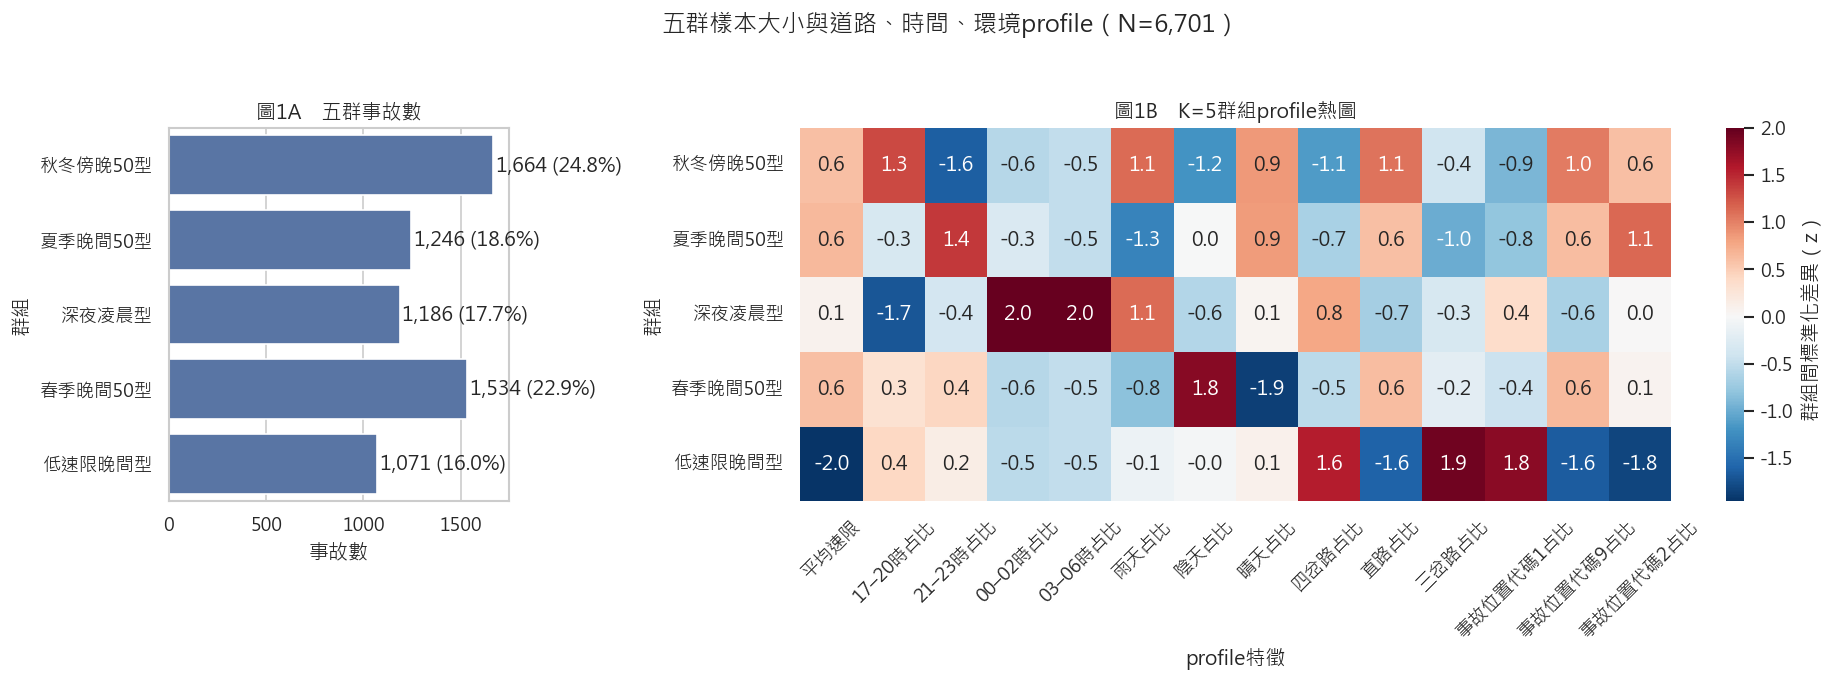

In [6]:
# 產生精簡且可解讀的profile特徵，再跨五群標準化以顯示相對高低。
profile_feature_rows = []
for cluster_name, group in analysis.groupby('cluster_name', observed=True):
    profile_feature_rows.append({
        '群組': cluster_name,
        '平均速限': group['speed_limit'].mean(),
        '17–20時占比': group['time_period'].eq('17–20時').mean(),
        '21–23時占比': group['time_period'].eq('21–23時').mean(),
        '00–02時占比': group['time_period'].eq('00–02時').mean(),
        '03–06時占比': group['time_period'].eq('03–06時').mean(),
        '雨天占比': group['weather_code'].eq(6).mean(),
        '陰天占比': group['weather_code'].eq(7).mean(),
        '晴天占比': group['weather_code'].eq(8).mean(),
        '四岔路占比': group['road_form_code'].eq(4).mean(),
        '直路占比': group['road_form_code'].eq(14).mean(),
        '三岔路占比': group['road_form_code'].eq(3).mean(),
        '事故位置代碼1占比': group['crash_position_code'].eq(1).mean(),
        '事故位置代碼9占比': group['crash_position_code'].eq(9).mean(),
        '事故位置代碼2占比': group['crash_position_code'].eq(2).mean(),
    })
profile_features = pd.DataFrame(profile_feature_rows).set_index('群組')
profile_z = (profile_features - profile_features.mean()) / profile_features.std(ddof=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={'width_ratios': [1, 3.2]})
sizes = analysis['cluster_name'].value_counts().reindex(cluster_order)
sns.barplot(x=sizes.values, y=sizes.index, ax=axes[0], color='#4C72B0')
axes[0].set(title='圖1A　五群事故數', xlabel='事故數', ylabel='群組')
for index, value in enumerate(sizes.values):
    axes[0].text(value + 15, index, f'{value:,} ({value / len(analysis) * 100:.1f}%)', va='center')
sns.heatmap(profile_z, cmap='RdBu_r', center=0, annot=True, fmt='.1f',
            cbar_kws={'label': '群組間標準化差異（z）'}, ax=axes[1])
axes[1].set(title='圖1B　K=5群組profile熱圖', xlabel='profile特徵', ylabel='群組')
axes[1].tick_params(axis='x', rotation=45)
fig.suptitle('五群樣本大小與道路、時間、環境profile（N=6,701）', y=1.03)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'k5_cluster_profile.png', bbox_inches='tight')
plt.show()
profile_features.to_csv(ASSET_DIR / 'k5_profile_features.csv', encoding='utf-8-sig')


表6　各群照明狀況比例與Wilson 95%信賴區間（各群照明皆可判定）


,群組,照明狀況,件數,分母,比例,95%CI下限,95%CI上限
0,秋冬傍晚50型,有照明且開啟,1548,1664,0.930288,0.917036,0.941559
1,秋冬傍晚50型,有照明未開啟或故障,93,1664,0.055889,0.045841,0.067984
2,秋冬傍晚50型,無照明,23,1664,0.013822,0.009228,0.020656
3,夏季晚間50型,有照明且開啟,1176,1246,0.943820,0.929617,0.955295
4,夏季晚間50型,有照明未開啟或故障,56,1246,0.044944,0.034772,0.057913
5,夏季晚間50型,無照明,14,1246,0.011236,0.006705,0.018772
6,深夜凌晨型,有照明且開啟,1066,1186,0.898820,0.880348,0.914715
7,深夜凌晨型,有照明未開啟或故障,93,1186,0.078415,0.064441,0.095111
8,深夜凌晨型,無照明,27,1186,0.022766,0.015692,0.032920
9,春季晚間50型,有照明且開啟,1462,1534,0.953064,0.941301,0.962563


{'lighting_chi_square': 35.04760136203536, 'degrees_of_freedom': 8, 'p_value': 2.620988393132261e-05, 'cramers_v': 0.05113807119141262, 'minimum_expected_count': 15.503208476346813}


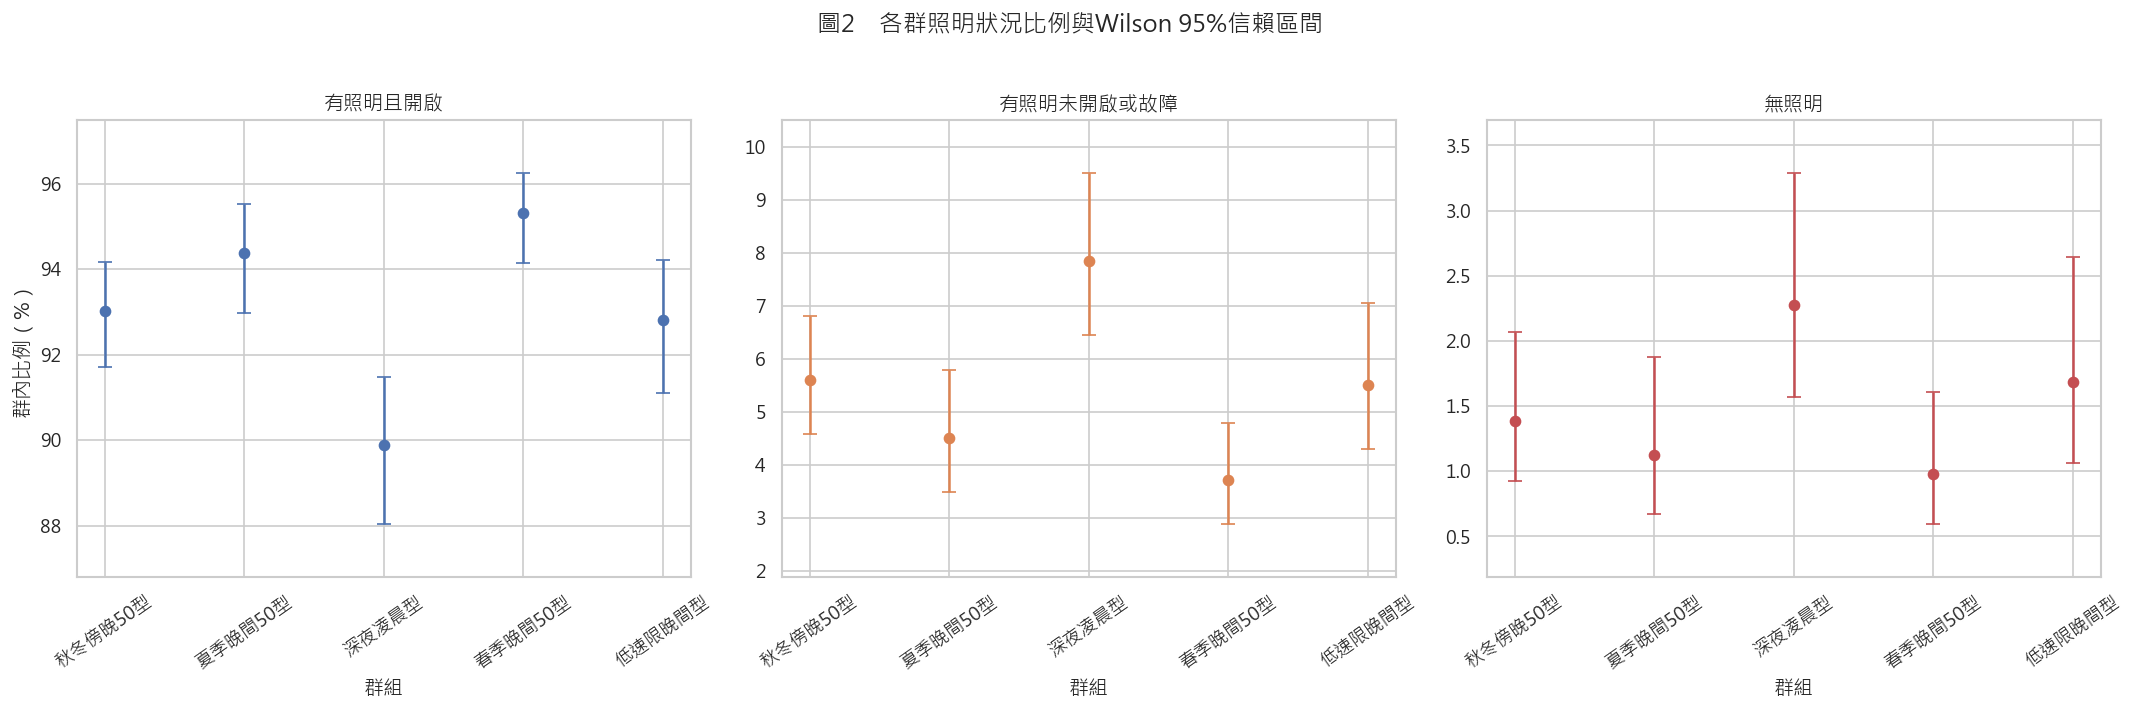

In [7]:
def wilson_interval(successes, n, alpha=0.05):
    low, high = proportion_confint(successes, n, alpha=alpha, method='wilson')
    return float(low), float(high)

LIGHTING_LABELS = {5: '有照明且開啟', 6: '有照明未開啟或故障', 7: '無照明'}
lighting_rows = []
for cluster_name, group in analysis.groupby('cluster_name', observed=True):
    n = group['光線'].notna().sum()
    for code, label in LIGHTING_LABELS.items():
        count = int(group['光線'].eq(code).sum())
        low, high = wilson_interval(count, n)
        lighting_rows.append({
            '群組': cluster_name, '照明狀況': label, '件數': count, '分母': n,
            '比例': count / n, '95%CI下限': low, '95%CI上限': high,
        })
lighting_table = pd.DataFrame(lighting_rows)
print('表6　各群照明狀況比例與Wilson 95%信賴區間（各群照明皆可判定）')
display(lighting_table)
lighting_table.to_csv(ASSET_DIR / 'k5_lighting_proportions.csv', index=False, encoding='utf-8-sig')

lighting_cross = pd.crosstab(analysis['cluster_name'], analysis['光線']).reindex(
    index=cluster_order, columns=[5, 6, 7], fill_value=0,
)
chi2, lighting_p, dof, expected = chi2_contingency(lighting_cross)
cramers_v = np.sqrt(chi2 / (lighting_cross.to_numpy().sum() * min(lighting_cross.shape[0] - 1, lighting_cross.shape[1] - 1)))
assert expected.min() >= 5
print({'lighting_chi_square': chi2, 'degrees_of_freedom': dof,
       'p_value': lighting_p, 'cramers_v': cramers_v, 'minimum_expected_count': expected.min()})

fig, axes = plt.subplots(1, 3, figsize=(18, 5.8), sharex=True)
colors = {'有照明且開啟': '#4C72B0', '有照明未開啟或故障': '#DD8452', '無照明': '#C44E52'}
x = np.arange(len(cluster_order))
for ax, label in zip(axes, LIGHTING_LABELS.values()):
    subset = lighting_table[lighting_table['照明狀況'].eq(label)].set_index('群組').reindex(cluster_order)
    y = subset['比例'].to_numpy() * 100
    lower = subset['95%CI下限'].to_numpy() * 100
    upper = subset['95%CI上限'].to_numpy() * 100
    yerr = np.vstack([y - lower, upper - y])
    ax.errorbar(x, y, yerr=yerr, fmt='o', capsize=4, color=colors[label])
    margin = max((upper.max() - lower.min()) * 0.15, 0.25)
    ax.set_ylim(max(0, lower.min() - margin), upper.max() + margin)
    ax.set(title=label, xlabel='群組', xticks=x, xticklabels=cluster_order)
    ax.tick_params(axis='x', rotation=35)
axes[0].set_ylabel('群內比例（%）')
fig.suptitle('圖2　各群照明狀況比例與Wilson 95%信賴區間', y=1.02)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'k5_lighting_proportions.png', bbox_inches='tight')
plt.show()


表7　各群24小時內死亡事故比例與Wilson 95%信賴區間（總死亡事故數很少）


,群組,死亡事故數,分母,死亡事故比例,95%CI下限,95%CI上限
0,秋冬傍晚50型,2,1664,0.001202,0.000330,0.004372
1,夏季晚間50型,4,1246,0.003210,0.001249,0.008225
2,深夜凌晨型,15,1186,0.012648,0.007679,0.020763
3,春季晚間50型,3,1534,0.001956,0.000665,0.005734
4,低速限晚間型,2,1071,0.001867,0.000512,0.006783


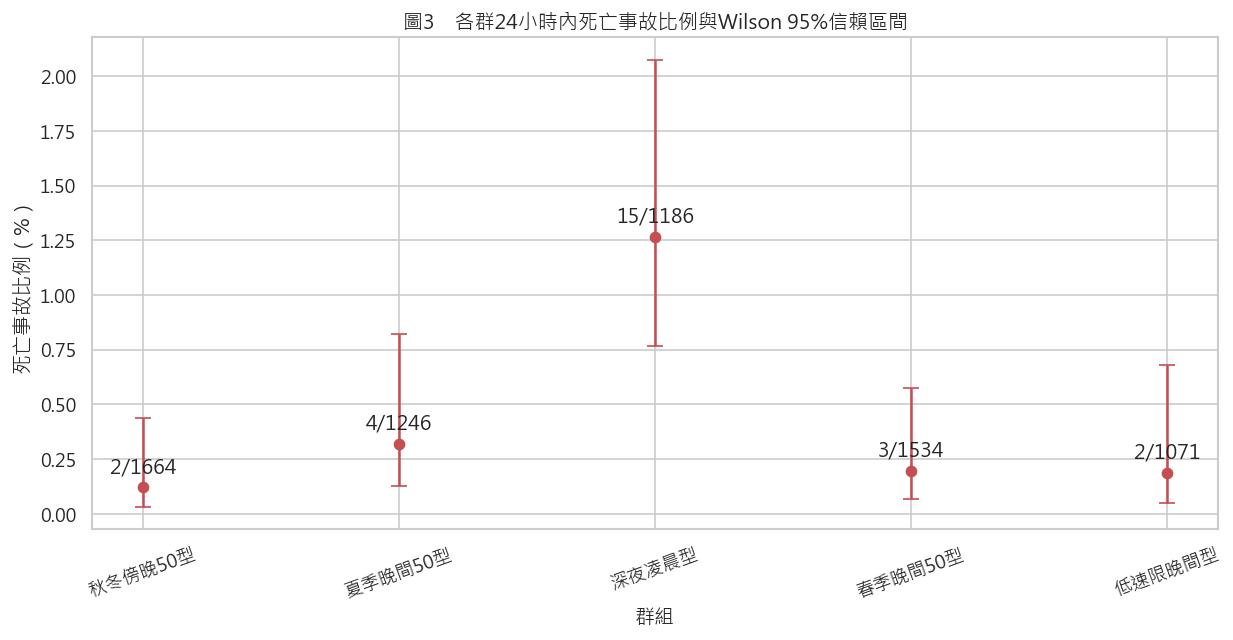

{'fatal_events_total': 26, 'note': '死亡事件稀少，只報告比例與Wilson信賴區間，不建立複雜模型。'}


In [8]:
fatal_rows = []
for cluster_name, group in analysis.groupby('cluster_name', observed=True):
    n = group['fatal24'].notna().sum()
    count = int(group['fatal24'].eq(1).sum())
    low, high = wilson_interval(count, n)
    fatal_rows.append({
        '群組': cluster_name, '死亡事故數': count, '分母': n, '死亡事故比例': count / n,
        '95%CI下限': low, '95%CI上限': high,
    })
fatal_table = pd.DataFrame(fatal_rows)
print('表7　各群24小時內死亡事故比例與Wilson 95%信賴區間（總死亡事故數很少）')
display(fatal_table)
fatal_table.to_csv(ASSET_DIR / 'k5_fatal_proportions.csv', index=False, encoding='utf-8-sig')

fig, ax = plt.subplots(figsize=(10.5, 5.5))
y = fatal_table['死亡事故比例'].to_numpy() * 100
yerr = np.vstack([y - fatal_table['95%CI下限'].to_numpy() * 100,
                  fatal_table['95%CI上限'].to_numpy() * 100 - y])
ax.errorbar(np.arange(len(fatal_table)), y, yerr=yerr, fmt='o', capsize=5, color='#C44E52')
for index, row in fatal_table.iterrows():
    ax.annotate(f"{int(row['死亡事故數'])}/{int(row['分母'])}",
                (index, row['死亡事故比例'] * 100), xytext=(0, 9),
                textcoords='offset points', ha='center')
ax.set(title='圖3　各群24小時內死亡事故比例與Wilson 95%信賴區間',
       xlabel='群組', ylabel='死亡事故比例（%）', xticks=np.arange(len(fatal_table)),
       xticklabels=fatal_table['群組'])
ax.tick_params(axis='x', rotation=20)
fig.tight_layout()
fig.savefig(ASSET_DIR / 'k5_fatal_proportions.png', bbox_inches='tight')
plt.show()
print({'fatal_events_total': int(analysis['fatal24'].sum()),
       'note': '死亡事件稀少，只報告比例與Wilson信賴區間，不建立複雜模型。'})


In [9]:
asset_manifest = pd.DataFrame([
    {'asset': path.name, 'bytes': path.stat().st_size, 'sha256': sha256_file(path)}
    for path in sorted(ASSET_DIR.iterdir()) if path.is_file()
])
print('表8　本階段支援檔案清單')
display(asset_manifest)


表8　本階段支援檔案清單


,asset,bytes,sha256
0,k5_cluster_profile.csv,2705,99c0eb2cade2633025b72a18d1cac486970994dbcca33a...
1,k5_cluster_profile.png,171867,d45c44e4ee129df27e3ff4d344a38d5278e37763620e96...
2,k5_fatal_proportions.csv,526,b1103e9e103d2bb74db3f4de8185b7425595be295f7022...
3,k5_fatal_proportions.png,62976,05ebf2758fdfb0e4aab2306e0e1040447d65f36f266d2a...
4,k5_lighting_proportions.csv,1661,13825e198fe2816ec7c27959fd52ffa0b8a1cbfe9ae745...
5,k5_lighting_proportions.png,79512,c409a47634666344c9966c4807529589aa7ea2b7d08aa4...
6,k5_profile_features.csv,1562,f448ef6ab9da53fa52aea46b8ade5d0673c118775c82b4...
7,primary_k5_assignments.csv,176290,07a88ce85fdd025b7d3ebda798c77ae9896f95df134362...


## 結果解讀與限制

主要K=5分群將6,701件事故分成五個大小尚可的群組，最小群仍有1,071件。秋冬傍晚50型主要集中於10月至1月及17–20時；夏季晚間50型集中於6月至9月及19–22時；春季晚間50型集中於2月至5月及18–22時；低速限晚間型的速限中位數為30 km/h；深夜凌晨型集中於22時至翌日6時。五群的主要道路類別多為代碼5，常見道路型態仍以四岔路、直路及三岔路為主，顯示K=5的區隔主要來自時間、季節與速限，而非截然不同的道路環境。

尺度敏感度方面，一般 one-hot與類別區塊加權K=5的ARI為0.843，經最佳標籤對齊後有93.2%的事故落在對應群。這支持五群並非完全由單一尺度設定製造，但仍有約6.8%事故會隨權重設定改變群別。

照明方面，深夜凌晨型有照明未開啟／故障93件（7.84%）、無照明27件（2.28%），合計10.12%，為五群最高；春季晚間50型合計4.69%最低。照明三分類與群組的卡方統計量為35.05、自由度8、p=0.000026，所有期望次數皆大於5；但Cramér’s V只有0.051，表示樣本雖足以偵測差異，關聯強度很小。這些差異也可能反映道路、時段或未觀測交通量的組成，不是照明效果。

死亡事故方面，全樣本僅26件。深夜凌晨型有15件、比例1.26%（Wilson 95% CI 0.77%–2.08%）；其他群各2至4件，比例約0.12%至0.32%。深夜凌晨型的描述性比例明顯較高，但事件稀少且未控制暴露量或其他混淆因素，因此不以此建立複雜模型，也不能推論深夜或照明造成死亡。

本分析只描述事故案件內的群組差異。照明、死亡、道路型態及時間可能同時受到交通量、土地使用與道路功能等未觀測因素影響；群組間比例不同不代表照明造成死亡，也不能換算成全市道路事故率。K=5名稱是profile摘要，不代表真實世界存在固定且互斥的事故類型。死亡事故數很少，信賴區間較寬，因此不以少數事件建立複雜模型或作強因果解讀。
